# FIGNN — Final Stage 1 and Stage 2 Demonstration

This notebook is a read-only demonstration of the final FIGNN evaluation
pipeline.

No training, retraining, checkpoint generation, or new evaluation
results are produced.

## Stage 1 — Unseen-subject representation transfer

For a representative held-out subject, the notebook:

- loads the corresponding fold-specific LOSO FIGNN checkpoint;
- loads the corresponding training-derived normalization statistics;
- generates latent embeddings;
- visualizes the 64-D learned representation;
- compares the held-out subject trajectory with the population trajectory;
- demonstrates trajectory-shape similarity using Procrustes alignment.

The quantitative Stage-1 evidence for all 29 held-out subjects is loaded
from the authoritative LOSO evaluation artifacts.

## Stage 2 — Frozen-encoder geometric calibration

The demonstration uses the same fold-specific frozen encoder and compares
four 64-D estimates of the held-out subject's 1-back latent centroid:

1. population-only;
2. midpoint;
3. regression;
4. frozen geometric calibration.

The true held-out 1-back centroid is used only as the evaluation target.

No FIGNN parameters are updated during Stage 2.

In [28]:
# ============================================================
# 0. SETUP
# ============================================================

import os
import sys
import json
import pickle
import copy

import numpy as np
import pandas as pd
import torch

import plotly.graph_objects as go
import plotly.express as px

from scipy.spatial import procrustes
from sklearn.decomposition import PCA
from torch_geometric.loader import DataLoader

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = os.path.abspath("..")

print("Project root:", PROJECT_ROOT)

GRAPHS_PATH = (
    "/lp-dev/24BCE1793/data/processed/"
    "all_graphs_29sub.pkl"
)

LOSO_ROOT = (
    "/lp-dev/24BCE1793/outputs/loso"
)

STAGE1_RESULTS_ROOT = (
    "/lp-dev/24BCE1793/outputs/"
    "evaluation_loso_all29"
)

STAGE2_DISTANCES_PATH = (
    "/lp-dev/24BCE1793/outputs/"
    "stage2_centroid_64D_distances.csv"
)

STAGE2_CALIBRATION_PATH = (
    "/lp-dev/24BCE1793/outputs/"
    "stage2_calibration_comparison_64D.csv"
)


# ------------------------------------------------------------
# Representative subject for interactive demonstration
# ------------------------------------------------------------

DEMO_SUBJECT = 17

TASK_LABELS = [0, 1, 2]

LABEL_NAMES = {
    0: "0-back",
    1: "1-back",
    2: "2-back"
}


# ------------------------------------------------------------
# Imports from project
# ------------------------------------------------------------

sys.path.insert(0, PROJECT_ROOT)

from src.models.model import FIGNNEncoder


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)
print("Demo subject:", DEMO_SUBJECT)

Project root: /home/nvidia/24BCE1793/fignn_cni__project
Using device: cuda
Demo subject: 17


In [29]:
# ============================================================
# 1. HELPERS
# ============================================================

def get_subject(graph):
    return int(graph.subject)


def get_label(graph):
    return int(graph.y.item())


def normalize_graphs(graphs, mean, std):

    normalized = []

    for graph in graphs:

        g = copy.copy(graph)

        g.x = (
            g.x.clone() - mean
        ) / std

        normalized.append(g)

    return normalized


@torch.no_grad()
def encode_graphs(
    model,
    graphs,
    mean,
    std,
    device,
    batch_size=128
):

    normalized = normalize_graphs(
        graphs,
        mean,
        std
    )

    loader = DataLoader(
        normalized,
        batch_size=batch_size,
        shuffle=False
    )

    embeddings = []
    labels = []

    model.eval()

    for batch in loader:

        batch = batch.to(device)

        z = model(batch)

        embeddings.append(
            z.detach().cpu().numpy()
        )

        labels.append(
            batch.y.view(-1).cpu().numpy()
        )

    return (
        np.vstack(embeddings),
        np.concatenate(labels)
    )


def condition_centroids(
    embeddings,
    labels
):

    centroids = {}

    for label in TASK_LABELS:

        centroids[label] = (
            embeddings[labels == label]
            .mean(axis=0)
        )

    return centroids


def trajectory_array(centroids):

    return np.vstack([
        centroids[0],
        centroids[1],
        centroids[2]
    ])

In [30]:
# ============================================================
# 2. LOAD FINAL GRAPH DATA
# ============================================================

print("Loading graphs...")

with open(GRAPHS_PATH, "rb") as f:
    all_graphs = pickle.load(f)

print("Total graphs:", len(all_graphs))

subjects = sorted(
    set(get_subject(g) for g in all_graphs)
)

print("Subjects:", subjects)

task_graphs = [
    g for g in all_graphs
    if get_label(g) in TASK_LABELS
]

print("Task graphs:", len(task_graphs))

Loading graphs...
Total graphs: 27666
Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Task graphs: 25056


In [31]:
# ============================================================
# 3. LOAD REPRESENTATIVE FROZEN LOSO MODEL
# ============================================================

CHECKPOINT = os.path.join(
    LOSO_ROOT,
    f"subject_{DEMO_SUBJECT:02d}",
    "fignn_best.pth"
)

print("Checkpoint:")
print(CHECKPOINT)

model = FIGNNEncoder().to(device)

state_dict = torch.load(
    CHECKPOINT,
    map_location=device
)

model.load_state_dict(state_dict)

model.eval()

print("Frozen LOSO model loaded successfully.")

Checkpoint:
/lp-dev/24BCE1793/outputs/loso/subject_17/fignn_best.pth
Frozen LOSO model loaded successfully.


In [32]:
# ============================================================
# 4. LOAD FOLD-SPECIFIC NORMALIZATION STATISTICS
# ============================================================

NORMALISATION_PATH = os.path.join(
    LOSO_ROOT,
    f"subject_{DEMO_SUBJECT:02d}",
    "normalisation_stats.pt"
)

stats = torch.load(
    NORMALISATION_PATH,
    map_location="cpu",
    weights_only=False
)

mean = stats["mean"].float()
std = stats["std"].float().clamp(min=1e-8)

print("Fold-specific normalization loaded.")
print("Normalization:", NORMALISATION_PATH)
print("Feature dimension:", len(mean))

Fold-specific normalization loaded.
Normalization: /lp-dev/24BCE1793/outputs/loso/subject_17/normalisation_stats.pt
Feature dimension: 4


In [33]:
# ============================================================
# 5. CONSTRUCT DEMO LOSO SPLIT
# ============================================================

train_graphs = [
    g for g in task_graphs
    if get_subject(g) != DEMO_SUBJECT
]

test_graphs = [
    g for g in task_graphs
    if get_subject(g) == DEMO_SUBJECT
]

print(
    f"Training subjects: "
    f"{len(set(get_subject(g) for g in train_graphs))}"
)

print(
    f"Held-out subject graphs: "
    f"{len(test_graphs)}"
)

Training subjects: 28
Held-out subject graphs: 864


In [34]:
# ============================================================
# 6. GENERATE DEMO EMBEDDINGS
# ============================================================

print("Encoding held-out subject...")

z_test, y_test = encode_graphs(
    model=model,
    graphs=test_graphs,
    mean=mean,
    std=std,
    device=device
)
assert DEMO_SUBJECT not in {
    get_subject(g) for g in train_graphs
}

assert DEMO_SUBJECT in {
    get_subject(g) for g in test_graphs
}

assert len(
    set(get_subject(g) for g in train_graphs)
) == 28
print("Held-out embeddings:", z_test.shape)

Encoding held-out subject...
Held-out embeddings: (864, 64)


/lp-dev/24BCE1793/fignn_env/lib/python3.13/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/lp-dev/24BCE1793/fignn_env/lib/python3.13/site-packages/sklearn/manifold/_mds.py:760: FutureWarning: Use metric_mds=True instead of metric=True. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


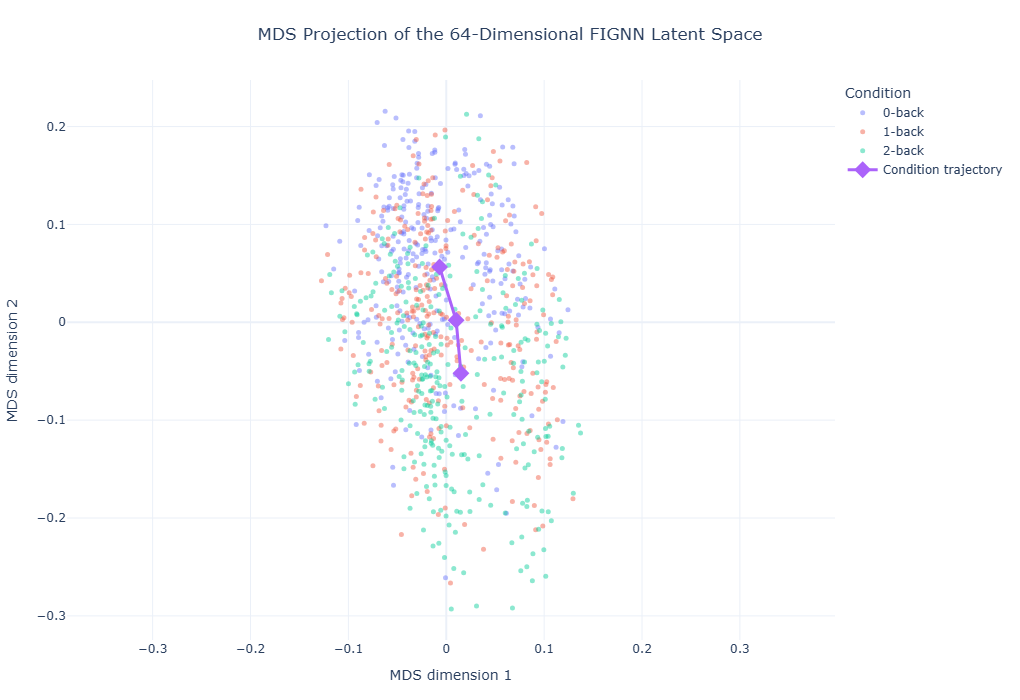

In [35]:
# ============================================================
# 7. LATENT SPACE VISUALIZATION — MDS
# ============================================================

from sklearn.manifold import MDS


# ------------------------------------------------------------
# True 64-D condition centroids
# ------------------------------------------------------------

centroids = np.vstack([
    z_test[y_test == 0].mean(axis=0),
    z_test[y_test == 1].mean(axis=0),
    z_test[y_test == 2].mean(axis=0)
])


# ------------------------------------------------------------
# Embed trials + centroids together
# ------------------------------------------------------------

z_mds_input = np.vstack([
    z_test,
    centroids
])


mds = MDS(
    n_components=2,
    metric=True,
    random_state=42,
    n_init=4,
    max_iter=300
)

z_2d = mds.fit_transform(z_mds_input)


# ------------------------------------------------------------
# Split trial and centroid coordinates
# ------------------------------------------------------------

sample_coords = z_2d[:-3]
centroid_coords = z_2d[-3:]


# ------------------------------------------------------------
# Trial-level dataframe
# ------------------------------------------------------------

plot_df = pd.DataFrame({
    "MDS 1": sample_coords[:, 0],
    "MDS 2": sample_coords[:, 1],
    "Condition": [
        LABEL_NAMES[int(y)]
        for y in y_test
    ]
})


# ------------------------------------------------------------
# Individual trial embeddings
# ------------------------------------------------------------

fig = px.scatter(
    plot_df,
    x="MDS 1",
    y="MDS 2",
    color="Condition",
    opacity=0.45
)


fig.update_traces(
    marker=dict(size=5)
)


# ------------------------------------------------------------
# Centroid trajectory
#
# The line shows:
# 0-back → 1-back → 2-back
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=centroid_coords[:, 0],
        y=centroid_coords[:, 1],
        mode="lines+markers",
        name="Condition trajectory",
        marker=dict(
            size=13,
            symbol="diamond"
        ),
        line=dict(
            width=3
        ),
        text=[
            "0-back centroid",
            "1-back centroid",
            "2-back centroid"
        ],
        hovertemplate=(
            "%{text}<br>"
            "MDS 1: %{x:.4f}<br>"
            "MDS 2: %{y:.4f}"
            "<extra></extra>"
        )
    )
)


# ------------------------------------------------------------
# Paper-style layout
# ------------------------------------------------------------

fig.update_layout(
    template="plotly_white",

    title=dict(
        text=(
            "MDS Projection of the 64-Dimensional FIGNN Latent Space"
        ),
        x=0.5,
        xanchor="center"
    ),

    height=700,
    width=850,

    legend=dict(
        title="Condition",
        x=1.01,
        y=1
    ),

    margin=dict(
        l=60,
        r=160,
        t=80,
        b=60
    )
)


# ------------------------------------------------------------
# Equal physical scale
#
# Important because this is a distance-preserving visualization.
# ------------------------------------------------------------

fig.update_yaxes(
    title="MDS dimension 2",
    scaleanchor="x",
    scaleratio=1
)

fig.update_xaxes(
    title="MDS dimension 1"
)


fig.show()

,Band,Learned weight
0,delta,0.216974
1,theta,0.202988
2,alpha,0.233300
3,beta,0.346738


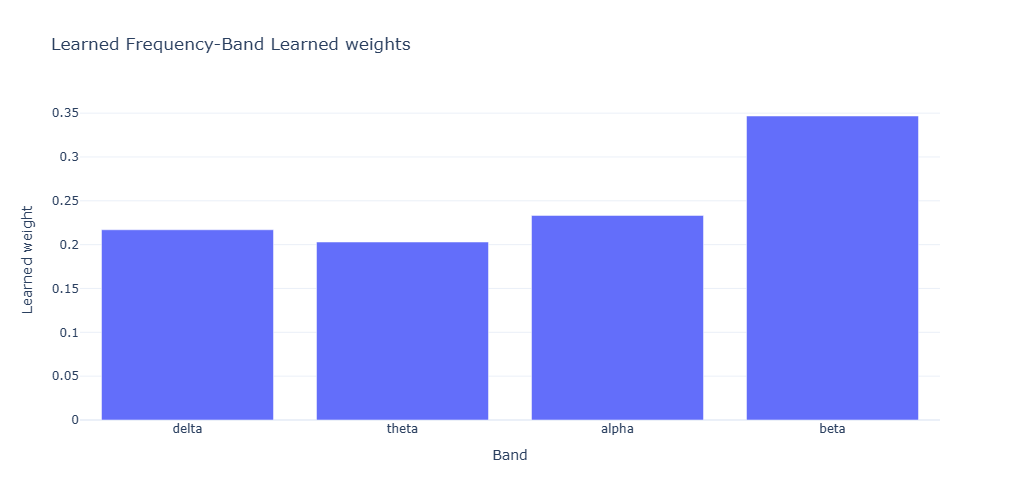

In [37]:
# ============================================================
# 8. LEARNED FREQUENCY-BAND WEIGHTS
# ============================================================

band_weights = (
    model.get_band_importance()
)

band_df = pd.DataFrame({
    "Band": list(band_weights.keys()),
    "Learned weight": list(
        band_weights.values()
    )
})

display(band_df.round(6))

fig = px.bar(
    band_df,
    x="Band",
    y="Learned weight",
    title="Learned Frequency-Band Learned weights"
)

fig.update_layout(
    template="plotly_white",
    height=500
)

fig.show()

In [41]:
# ============================================================
# 9. BUILD POPULATION WORKLOAD TRAJECTORY
# ============================================================

training_subjects = sorted(
    set(
        get_subject(g)
        for g in train_graphs
    )
)

population_centroids = []

for label in TASK_LABELS:

    subject_centroids = []

    for subject in training_subjects:

        subject_graphs = [
            g for g in train_graphs
            if get_subject(g) == subject
            and get_label(g) == label
        ]

        z_subject, _ = encode_graphs(
            model=model,
            graphs=subject_graphs,
            mean=mean,
            std=std,
            device=device
        )

        subject_centroids.append(
            z_subject.mean(axis=0)
        )

    population_centroids.append(
        np.mean(
            subject_centroids,
            axis=0
        )
    )

population_centroids = np.vstack(
    population_centroids
)

subject_centroids = trajectory_array(
    condition_centroids(
        z_test,
        y_test
    )
)

print(
    "Population trajectory shape:",
    population_centroids.shape
)

print(
    "Subject trajectory shape:",
    subject_centroids.shape
)

Population trajectory shape: (3, 64)
Subject trajectory shape: (3, 64)


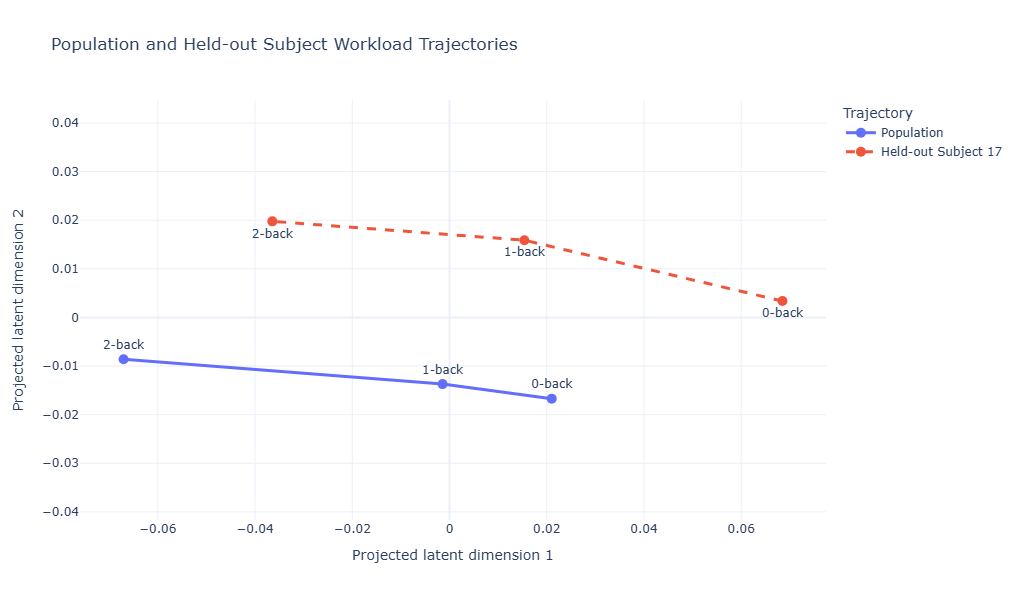

In [42]:
# ============================================================
# 10. POPULATION vs SUBJECT TRAJECTORY
# ============================================================

combined = np.vstack([
    population_centroids,
    subject_centroids
])


# ------------------------------------------------------------
# Joint projection
#
# PCA is fitted ONCE to all six 64-D centroids so population
# and held-out subject trajectories share the same coordinate
# system.
# ------------------------------------------------------------

trajectory_pca = PCA(
    n_components=2
)

combined_2d = trajectory_pca.fit_transform(
    combined
)

population_2d = combined_2d[:3]

subject_2d = combined_2d[3:]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig = go.Figure()


# Population trajectory
fig.add_trace(
    go.Scatter(
        x=population_2d[:, 0],
        y=population_2d[:, 1],

        mode="lines+markers+text",

        text=[
            "0-back",
            "1-back",
            "2-back"
        ],

        textposition="top center",

        name="Population",

        marker=dict(
            size=10
        ),

        line=dict(
            width=3
        )
    )
)


# Held-out subject trajectory
fig.add_trace(
    go.Scatter(
        x=subject_2d[:, 0],
        y=subject_2d[:, 1],

        mode="lines+markers+text",

        text=[
            "0-back",
            "1-back",
            "2-back"
        ],

        textposition="bottom center",

        name=(
            f"Held-out Subject {DEMO_SUBJECT}"
        ),

        marker=dict(
            size=10
        ),

        line=dict(
            width=3,
            dash="dash"
        )
    )
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

fig.update_layout(
    title=(
        "Population and Held-out Subject "
        "Workload Trajectories"
    ),

    xaxis_title=(
        "Projected latent dimension 1"
    ),

    yaxis_title=(
        "Projected latent dimension 2"
    ),

    template="plotly_white",

    height=600,

    width=900,

    legend=dict(
        title="Trajectory"
    )
)


# ------------------------------------------------------------
# Equal geometric scaling
# ------------------------------------------------------------

fig.update_yaxes(
    scaleanchor="x",
    scaleratio=1
)


fig.show()

Representative subject: 17
Procrustes disparity: 0.092333
Shape similarity: 0.907667
PCA variance shown: 100.00%


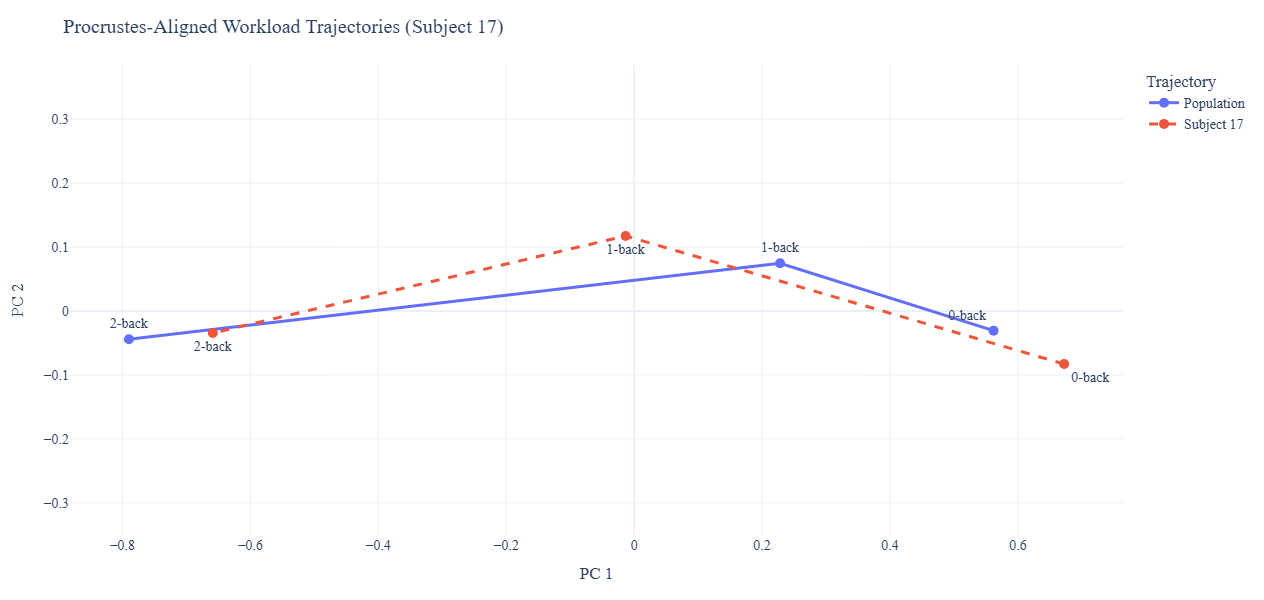


Saved Procrustes figure.


In [43]:
# ============================================================
# 11. PROCRUSTES TRAJECTORY SHAPE COMPARISON
# ============================================================

from scipy.spatial import procrustes
from sklearn.decomposition import PCA
import plotly.graph_objects as go
import numpy as np


# ------------------------------------------------------------
# 1. Procrustes alignment in full 64-D latent space
# ------------------------------------------------------------

population_mtx, subject_mtx, disparity = procrustes(
    population_centroids,
    subject_centroids
)

shape_similarity = 1.0 - disparity

print(f"Representative subject: {DEMO_SUBJECT}")
print(f"Procrustes disparity: {disparity:.6f}")
print(f"Shape similarity: {shape_similarity:.6f}")


# ------------------------------------------------------------
# 2. PCA ONLY for 2-D visualization
# ------------------------------------------------------------

combined = np.vstack([
    population_mtx,
    subject_mtx
])

pca = PCA(n_components=2)

combined_2d = pca.fit_transform(combined)

population_2d = combined_2d[:3]
subject_2d = combined_2d[3:]


print(
    f"PCA variance shown: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)


# ------------------------------------------------------------
# 3. Condition labels
# ------------------------------------------------------------

conditions = [
    "0-back",
    "1-back",
    "2-back"
]


# ------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------

fig = go.Figure()


# ============================================================
# Population trajectory
# ============================================================

fig.add_trace(
    go.Scatter(
        x=population_2d[:, 0],
        y=population_2d[:, 1],

        mode="lines+markers+text",

        text=conditions,

        # Put population labels above/right of points
        textposition=[
            "top left",
            "top center",
            "top center"
        ],

        name="Population",

        marker=dict(
            size=10
        ),

        line=dict(
            width=3
        ),

        hovertemplate=(
            "Population"
            "<br>%{text}"
            "<br>PC1 = %{x:.3f}"
            "<br>PC2 = %{y:.3f}"
            "<extra></extra>"
        )
    )
)


# ============================================================
# Subject trajectory
# ============================================================

fig.add_trace(
    go.Scatter(
        x=subject_2d[:, 0],
        y=subject_2d[:, 1],

        mode="lines+markers+text",

        text=conditions,

        # Put subject labels below/right of points
        textposition=[
            "bottom right",
            "bottom center",
            "bottom center"
        ],

        name=f"Subject {DEMO_SUBJECT}",

        marker=dict(
            size=10
        ),

        line=dict(
            width=3,
            dash="dash"
        ),

        hovertemplate=(
            f"Subject {DEMO_SUBJECT}"
            "<br>%{text}"
            "<br>PC1 = %{x:.3f}"
            "<br>PC2 = %{y:.3f}"
            "<extra></extra>"
        )
    )
)


# ============================================================
# Layout
# ============================================================

fig.update_layout(
    template="plotly_white",

    width=850,
    height=600,

    margin=dict(
        l=70,
        r=30,
        t=65,
        b=65
    ),

    font=dict(
        family="Times New Roman",
        size=14
    ),

    title=(
        f"Procrustes-Aligned Workload Trajectories "
        f"(Subject {DEMO_SUBJECT})"
    ),

    xaxis_title="PC 1",
    yaxis_title="PC 2",

    legend=dict(
        title="Trajectory"
    )
)


# Preserve geometric aspect ratio
fig.update_yaxes(
    scaleanchor="x",
    scaleratio=1
)


fig.show()


# ============================================================
# Export
# ============================================================

fig.write_html(
    "fig_procrustes_subject17.html"
)

try:

    fig.write_image(
        "fig_procrustes_subject17.pdf",
        width=850,
        height=600,
        scale=2
    )

    fig.write_image(
        "fig_procrustes_subject17.png",
        width=1700,
        height=1200,
        scale=1
    )

    print("\nSaved Procrustes figure.")

except Exception as e:

    print(f"\nExport failed: {e}")
    print("If required: pip install -U kaleido")

In [44]:
# ============================================================
# 12. FINAL STAGE 1 — ALL 29 LOSO EVALUATION
# ============================================================

from scipy.spatial.distance import euclidean

with open(GRAPHS_PATH,"rb") as f:
    all_graphs = pickle.load(f)

all_graphs = [g for g in all_graphs if int(g.y.item()) != 3]


def load_fold_checkpoint(subject):
    fold_dir = os.path.join(LOSO_ROOT,f"subject_{subject:02d}")
    checkpoint = os.path.join(fold_dir,"fignn_best.pth")
    if not os.path.exists(checkpoint):
        raise FileNotFoundError(f"No checkpoint found for Subject {subject}: {fold_dir}")
    return checkpoint


def load_fold_normalisation(subject):
    stats_path=os.path.join(LOSO_ROOT,f"subject_{subject:02d}","normalisation_stats.pt")
    stats=torch.load(stats_path,map_location=device,weights_only=False)
    return stats["mean"],stats["std"]


def normalize_graphs(graphs,feature_mean,feature_std):
    feature_mean=feature_mean.detach().cpu()
    feature_std=feature_std.detach().cpu()
    out=[]
    for g in graphs:
        g=copy.deepcopy(g)
        g.x=(g.x-feature_mean)/(feature_std+1e-8)
        out.append(g)
    return out


def build_centroids(z,y,labels=[0,1,2]):
    return np.stack([z[y==label].mean(axis=0) for label in labels])


def trajectory_geometry(T):
    C0,C1,C2=T
    d01=np.linalg.norm(C1-C0)
    d02=np.linalg.norm(C2-C0)
    d12=np.linalg.norm(C2-C1)
    ratio01=d01/d02 if d02>0 else np.nan
    ratio12=d12/d02 if d02>0 else np.nan
    path_eff=d02/(d01+d12) if (d01+d12)>0 else np.nan
    v01=C1-C0
    v12=C2-C1
    cosine=np.dot(v01,v12)/(np.linalg.norm(v01)*np.linalg.norm(v12)) if np.linalg.norm(v01)>0 and np.linalg.norm(v12)>0 else np.nan
    angle=np.degrees(np.arccos(np.clip(cosine,-1,1))) if not np.isnan(cosine) else np.nan
    return {"d01":d01,"d02":d02,"d12":d12,"d01_d02":ratio01,"d12_d02":ratio12,"path_efficiency":path_eff,"angle_deg":angle}


def trajectory_position(T):
    C0,C1,C2=T
    v=C2-C0
    denom=np.dot(v,v)
    t=np.dot(C1-C0,v)/denom if denom>0 else np.nan
    projection=C0+t*v
    perpendicular=np.linalg.norm(C1-projection)
    centrality=1-abs(t-0.5)/0.5 if not np.isnan(t) else np.nan
    between=bool(0<=t<=1) if not np.isnan(t) else False
    return t,perpendicular,centrality,between


def procrustes_similarity(T_subject,T_population):
    _,_,disp=procrustes(T_population,T_subject)
    return 1-disp


def direction_cosine(T_subject,T_population):
    v_subject=T_subject[2]-T_subject[0]
    v_population=T_population[2]-T_population[0]
    denom=np.linalg.norm(v_subject)*np.linalg.norm(v_population)
    return float(np.dot(v_subject,v_population)/denom) if denom>0 else np.nan


stage1_rows=[]

for subject in range(1,30):

    print(f"\nEvaluating Subject {subject:02d}...",flush=True)

    train_graphs=[g for g in all_graphs if int(g.subject)!=subject]
    test_graphs=[g for g in all_graphs if int(g.subject)==subject]

    checkpoint=load_fold_checkpoint(subject)
    feature_mean,feature_std=load_fold_normalisation(subject)

    if not torch.is_tensor(feature_mean):
        feature_mean=torch.tensor(feature_mean,dtype=torch.float32)
    if not torch.is_tensor(feature_std):
        feature_std=torch.tensor(feature_std,dtype=torch.float32)

    train_graphs=normalize_graphs(train_graphs,feature_mean,feature_std)
    test_graphs=normalize_graphs(test_graphs,feature_mean,feature_std)

    model=FIGNNEncoder(node_in_dim=4,edge_dim=4,hidden_dim=128,latent_dim=64,n_heads=8,dropout=0.3).to(device)

    ckpt=torch.load(checkpoint,map_location=device,weights_only=False)
    state_dict=ckpt.get("model_state_dict",ckpt.get("state_dict",ckpt))
    model.load_state_dict(state_dict,strict=True)
    model.eval()

    def encode(graphs):
        loader=DataLoader(graphs,batch_size=128,shuffle=False)
        zs=[]
        ys=[]
        with torch.no_grad():
            for batch in loader:
                batch=batch.to(device)
                z=model(batch)
                zs.append(z.detach().cpu().numpy())
                ys.append(batch.y.detach().cpu().numpy())
        return np.concatenate(zs),np.concatenate(ys)

    train_z,train_y=encode(train_graphs)
    test_z,test_y=encode(test_graphs)

    population_trajectories=[]

    for s in range(1,30):
        if s==subject:
            continue
        z_s,y_s=encode([g for g in train_graphs if int(g.subject)==s])
        C_s=build_centroids(z_s,y_s)
        population_trajectories.append(C_s)

    population_T=np.mean(np.stack(population_trajectories),axis=0)

    subject_T=build_centroids(test_z,test_y)

    geometry=trajectory_geometry(subject_T)
    relative_position,perpendicular_distance,centrality,between=trajectory_position(subject_T)
    proc=procrustes_similarity(subject_T,population_T)
    dir_cos=direction_cosine(subject_T,population_T)

    stage1_rows.append({
        "subject":subject,
        "d01":geometry["d01"],
        "d02":geometry["d02"],
        "d12":geometry["d12"],
        "d01_d02":geometry["d01_d02"],
        "d12_d02":geometry["d12_d02"],
        "angle_deg":geometry["angle_deg"],
        "path_efficiency":geometry["path_efficiency"],
        "relative_1back_position":relative_position,
        "perpendicular_distance":perpendicular_distance,
        "centrality":centrality,
        "oneback_between":between,
        "procrustes_similarity":proc,
        "direction_cosine":dir_cos,
        "n_train_trajectories":len(population_trajectories),
        "checkpoint":checkpoint
    })

stage1_df=pd.DataFrame(stage1_rows).sort_values("subject").reset_index(drop=True)

os.makedirs(STAGE1_RESULTS_ROOT,exist_ok=True)

STAGE1_SUBJECT_METRICS=os.path.join(STAGE1_RESULTS_ROOT,"loso_all29_subject_metrics.csv")
stage1_df.to_csv(STAGE1_SUBJECT_METRICS,index=False)

print("\n============================================================")
print("STAGE 1 — 29-FOLD LOSO COMPLETE")
print("============================================================")
display(stage1_df.round(4))

print(f"\nSaved: {STAGE1_SUBJECT_METRICS}")


Evaluating Subject 01...

Evaluating Subject 02...

Evaluating Subject 03...

Evaluating Subject 04...

Evaluating Subject 05...

Evaluating Subject 06...

Evaluating Subject 07...

Evaluating Subject 08...

Evaluating Subject 09...

Evaluating Subject 10...

Evaluating Subject 11...

Evaluating Subject 12...

Evaluating Subject 13...

Evaluating Subject 14...

Evaluating Subject 15...

Evaluating Subject 16...

Evaluating Subject 17...

Evaluating Subject 18...

Evaluating Subject 19...

Evaluating Subject 20...

Evaluating Subject 21...

Evaluating Subject 22...

Evaluating Subject 23...

Evaluating Subject 24...

Evaluating Subject 25...

Evaluating Subject 26...

Evaluating Subject 27...

Evaluating Subject 28...

Evaluating Subject 29...

STAGE 1 — 29-FOLD LOSO COMPLETE


,subject,d01,d02,d12,d01_d02,d12_d02,angle_deg,path_efficiency,relative_1back_position,perpendicular_distance,centrality,oneback_between,procrustes_similarity,direction_cosine,n_train_trajectories,checkpoint
0,1,0.0121,0.0217,0.0149,0.5592,0.6888,73.957703,0.8013,0.4191,0.0080,0.8383,True,0.9034,-0.8348,28,/lp-dev/24BCE1793/outputs/loso/subject_01/fign...
1,2,0.0247,0.0885,0.0776,0.2790,0.8771,71.814201,0.8649,0.1542,0.0206,0.3085,True,0.9629,0.8755,28,/lp-dev/24BCE1793/outputs/loso/subject_02/fign...
2,3,0.0173,0.0442,0.0336,0.3920,0.7591,63.021198,0.8687,0.2887,0.0117,0.5774,True,0.9654,0.8543,28,/lp-dev/24BCE1793/outputs/loso/subject_03/fign...
3,4,0.0434,0.0674,0.0282,0.6450,0.4187,40.807701,0.9402,0.6204,0.0119,0.7593,True,0.8095,0.9548,28,/lp-dev/24BCE1793/outputs/loso/subject_04/fign...
4,5,0.0322,0.0599,0.0339,0.5372,0.5656,49.884998,0.9068,0.4843,0.0139,0.9686,True,0.9127,0.9430,28,/lp-dev/24BCE1793/outputs/loso/subject_05/fign...
5,6,0.0325,0.0597,0.0357,0.5439,0.5980,57.816399,0.8757,0.4691,0.0164,0.9383,True,0.9079,0.9520,28,/lp-dev/24BCE1793/outputs/loso/subject_06/fign...
6,7,0.0118,0.0360,0.0257,0.3282,0.7139,35.240101,0.9596,0.2991,0.0049,0.5981,True,0.9984,0.8621,28,/lp-dev/24BCE1793/outputs/loso/subject_07/fign...
7,8,0.0202,0.0455,0.0267,0.4450,0.5865,28.681299,0.9694,0.4270,0.0057,0.8540,True,0.9645,0.7657,28,/lp-dev/24BCE1793/outputs/loso/subject_08/fign...
8,9,0.0108,0.0645,0.0652,0.1678,1.0110,98.527199,0.8483,0.0030,0.0108,0.0060,True,0.9440,0.9650,28,/lp-dev/24BCE1793/outputs/loso/subject_09/fign...
9,10,0.0129,0.0695,0.0619,0.1857,0.8913,58.895199,0.9285,0.1200,0.0099,0.2400,True,0.9741,0.9458,28,/lp-dev/24BCE1793/outputs/loso/subject_10/fign...



Saved: /lp-dev/24BCE1793/outputs/evaluation_loso_all29/loso_all29_subject_metrics.csv


In [49]:
stage1_summary=pd.DataFrame({
    "Metric":["Procrustes similarity","Direction cosine","Path efficiency","d01/d02","d12/d02","Trajectory angle (°)","Relative 1B position","Perpendicular distance","Centrality","1B between 0B–2B","d01/d02 < 1"],
    "Result":[
        f"{stage1_df['procrustes_similarity'].mean():.4f} ± {stage1_df['procrustes_similarity'].std():.4f}",
        f"{stage1_df['direction_cosine'].mean():.4f} ± {stage1_df['direction_cosine'].std():.4f}",
        f"{stage1_df['path_efficiency'].mean():.4f} ± {stage1_df['path_efficiency'].std():.4f}",
        f"{stage1_df['d01_d02'].mean():.4f} ± {stage1_df['d01_d02'].std():.4f}",
        f"{stage1_df['d12_d02'].mean():.4f} ± {stage1_df['d12_d02'].std():.4f}",
        f"{stage1_df['angle_deg'].mean():.2f} ± {stage1_df['angle_deg'].std():.2f}",
        f"{stage1_df['relative_1back_position'].mean():.4f} ± {stage1_df['relative_1back_position'].std():.4f}",
        f"{stage1_df['perpendicular_distance'].mean():.4f} ± {stage1_df['perpendicular_distance'].std():.4f}",
        f"{stage1_df['centrality'].mean():.4f} ± {stage1_df['centrality'].std():.4f}",
        f"{stage1_df['oneback_between'].sum()} / 29 ({100*stage1_df['oneback_between'].mean():.2f}%)",
        f"{(stage1_df['d01_d02']<1).sum()} / 29 ({100*(stage1_df['d01_d02']<1).mean():.2f}%)"
    ]
})

display(stage1_summary)

,Metric,Result
0,Procrustes similarity,0.8775 ± 0.1548
1,Direction cosine,0.7854 ± 0.4036
2,Path efficiency,0.8192 ± 0.1704
3,d01/d02,0.4772 ± 0.2695
4,d12/d02,0.8239 ± 0.2839
5,Trajectory angle (°),73.20 ± 39.67
6,Relative 1B position,0.2705 ± 0.2906
7,Perpendicular distance,0.0135 ± 0.0088
8,Centrality,0.4214 ± 0.4572
9,1B between 0B–2B,23 / 29 (79.31%)


# Stage 2 — Direct 64-D geometry and calibration

Stage 2 evaluates personalization directly in the original FIGNN latent space.

Unlike the earlier trajectory-position experiment, the final evaluation does not use PCA, MDS, or another dimensionality reduction method for the error calculation.

All distances and prediction errors are computed directly in the 64-dimensional latent space.

In [48]:
# ============================================================
# 13. STAGE 2A — DIRECT 64-D CENTROID DISTANCES
# ============================================================

distance_df = pd.read_csv(
    STAGE2_DISTANCES_PATH
)

display(
    distance_df.round(6)
)


distance_summary = (
    distance_df[
        [
            "d_0B_1B",
            "d_1B_2B",
            "d_0B_2B"
        ]
    ]
    .agg(
        ["mean", "median", "std"]
    )
)

display(
    distance_summary.round(6)
)


count_01_lt_02 = (
    distance_df["d_0B_1B"]
    <
    distance_df["d_0B_2B"]
).sum()

count_12_lt_02 = (
    distance_df["d_1B_2B"]
    <
    distance_df["d_0B_2B"]
).sum()


print(
    f"Subjects where "
    f"0B–1B < 0B–2B: "
    f"{count_01_lt_02} / "
    f"{len(distance_df)}"
)

print(
    f"Subjects where "
    f"1B–2B < 0B–2B: "
    f"{count_12_lt_02} / "
    f"{len(distance_df)}"
)

,Subject,d_0B_1B,d_1B_2B,d_0B_2B,n_0B,n_1B,n_2B,0B_1B_closer_than_0B_2B,1B_2B_closer_than_0B_2B
0,1,0.012379,0.017373,0.016462,288,288,288,True,False
1,2,0.021116,0.115359,0.108966,288,288,288,True,False
2,3,0.019104,0.019634,0.031793,288,288,288,True,True
3,4,0.051977,0.029631,0.073259,288,288,288,True,True
4,5,0.029995,0.032870,0.054526,288,288,288,True,True
5,6,0.035939,0.049164,0.081527,288,288,288,True,True
6,7,0.010385,0.058360,0.063433,288,288,288,True,True
7,8,0.013892,0.022296,0.032622,288,288,288,True,True
8,9,0.030234,0.104460,0.079226,288,288,288,True,False
9,10,0.022960,0.060721,0.079713,288,288,288,True,True


,d_0B_1B,d_1B_2B,d_0B_2B
mean,0.028848,0.049792,0.062598
median,0.026277,0.044657,0.053526
std,0.016047,0.030968,0.035554


Subjects where 0B–1B < 0B–2B: 28 / 29
Subjects where 1B–2B < 0B–2B: 19 / 29


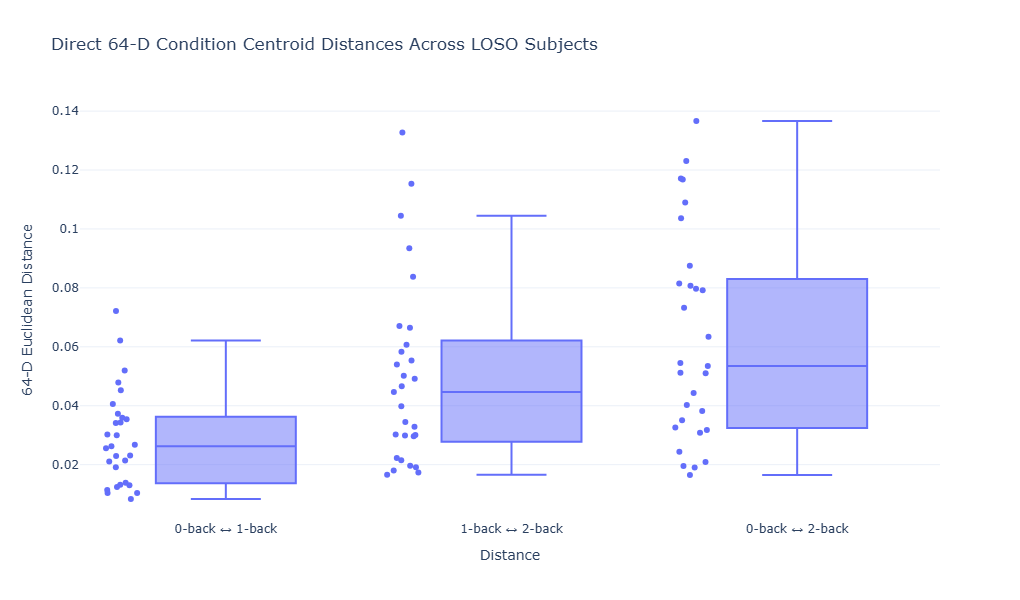

In [50]:
# ============================================================
# 14. 64-D CONDITION DISTANCE VISUALIZATION
# ============================================================

distance_long = distance_df.melt(
    id_vars="Subject",
    value_vars=[
        "d_0B_1B",
        "d_1B_2B",
        "d_0B_2B"
    ],
    var_name="Distance",
    value_name="64-D Euclidean Distance"
)

distance_long["Distance"] = (
    distance_long["Distance"]
    .replace({
        "d_0B_1B": "0-back ↔ 1-back",
        "d_1B_2B": "1-back ↔ 2-back",
        "d_0B_2B": "0-back ↔ 2-back"
    })
)


fig = px.box(
    distance_long,
    x="Distance",
    y="64-D Euclidean Distance",
    points="all",
    title=(
        "Direct 64-D Condition "
        "Centroid Distances Across LOSO Subjects"
    )
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()

In [51]:
# ============================================================
# 14A. LOAD FINAL STAGE 2 CALIBRATION RESULTS
# ============================================================

calibration_df = pd.read_csv(
    STAGE2_CALIBRATION_PATH
)

print("Final Stage 2 calibration results loaded.")

print(
    f"Rows: {len(calibration_df)}"
)

print(
    f"Subjects: "
    f"{calibration_df['subject'].nunique()}"
)

print(
    "Methods:",
    calibration_df["method"].unique().tolist()
)

display(
    calibration_df.head(12)
)

Final Stage 2 calibration results loaded.
Rows: 116
Subjects: 29
Methods: ['frozen_geometric', 'midpoint', 'population_only', 'regression']


,subject,method,error_64D,prediction_alpha,population_alpha,prediction_norm,true_1B_norm,rest_norm,two_back_norm,checkpoint
0,1,frozen_geometric,0.056798,0.690534,0.690534,0.989981,0.988499,0.996201,0.990700,/lp-dev/24BCE1793/outputs/loso/subject_01/fign...
1,1,midpoint,0.084958,0.500000,NaN,0.990620,0.988499,0.996201,0.990700,/lp-dev/24BCE1793/outputs/loso/subject_01/fign...
2,1,population_only,0.054337,NaN,NaN,0.990243,0.988499,0.996201,0.990700,/lp-dev/24BCE1793/outputs/loso/subject_01/fign...
3,1,regression,0.077864,NaN,NaN,0.995008,0.988499,0.996201,0.990700,/lp-dev/24BCE1793/outputs/loso/subject_01/fign...
4,2,frozen_geometric,0.024916,0.673947,0.673947,0.993008,0.995855,0.996939,0.996652,/lp-dev/24BCE1793/outputs/loso/subject_02/fign...
5,2,midpoint,0.026146,0.500000,NaN,0.992542,0.995855,0.996939,0.996652,/lp-dev/24BCE1793/outputs/loso/subject_02/fign...
6,2,population_only,0.071156,NaN,NaN,0.993546,0.995855,0.996939,0.996652,/lp-dev/24BCE1793/outputs/loso/subject_02/fign...
7,2,regression,0.062389,NaN,NaN,0.994025,0.995855,0.996939,0.996652,/lp-dev/24BCE1793/outputs/loso/subject_02/fign...
8,3,frozen_geometric,0.036172,0.669599,0.669599,0.988628,0.993317,0.991829,0.992721,/lp-dev/24BCE1793/outputs/loso/subject_03/fign...
9,3,midpoint,0.065468,0.500000,NaN,0.987981,0.993317,0.991829,0.992721,/lp-dev/24BCE1793/outputs/loso/subject_03/fign...


In [52]:
# ============================================================
# 15. FINAL STAGE 2 — FOUR-METHOD CALIBRATION COMPARISON
# ============================================================

METHOD_ORDER = [
    "population_only",
    "midpoint",
    "regression",
    "frozen_geometric",
]

method_labels = {
    "population_only": "Population-only",
    "midpoint": "Midpoint",
    "regression": "Regression",
    "frozen_geometric": "Frozen geometric",
}

stage2_summary = (
    calibration_df
    .groupby("method")["error_64D"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        count="count",
    )
    .reindex(METHOD_ORDER)
)

stage2_summary.index = [
    method_labels[m]
    for m in stage2_summary.index
]

display(
    stage2_summary.round(6)
)

baseline = (
    calibration_df[
        calibration_df["method"] == "population_only"
    ][
        ["subject", "error_64D"]
    ]
    .rename(
        columns={
            "error_64D":
            "population_error"
        }
    )
)

comparison = calibration_df.merge(
    baseline,
    on="subject",
    how="left"
)

comparison["error_reduction"] = (
    comparison["population_error"]
    - comparison["error_64D"]
)

comparison["improved"] = (
    comparison["error_64D"]
    < comparison["population_error"]
)

comparison_nonbaseline = comparison[
    comparison["method"] != "population_only"
]

summary_rows = []

for method in METHOD_ORDER[1:]:
    subset = comparison_nonbaseline[
        comparison_nonbaseline["method"] == method
    ]

    summary_rows.append({
        "Method": method_labels[method],
        "Mean error": subset["error_64D"].mean(),
        "Mean reduction": subset["error_reduction"].mean(),
        "Improved subjects": int(
            subset["improved"].sum()
        ),
        "Subjects": len(subset),
    })

comparison_summary = pd.DataFrame(
    summary_rows
)

display(
    comparison_summary.round(6)
)

,mean,std,median,count
Population-only,0.064860,0.031883,0.056985,29
Midpoint,0.052229,0.025477,0.050302,29
Regression,0.050849,0.030088,0.047213,29
Frozen geometric,0.034542,0.016811,0.029759,29


,Method,Mean error,Mean reduction,Improved subjects,Subjects
0,Midpoint,0.052229,0.012630,18,29
1,Regression,0.050849,0.014011,19,29
2,Frozen geometric,0.034542,0.030317,22,29


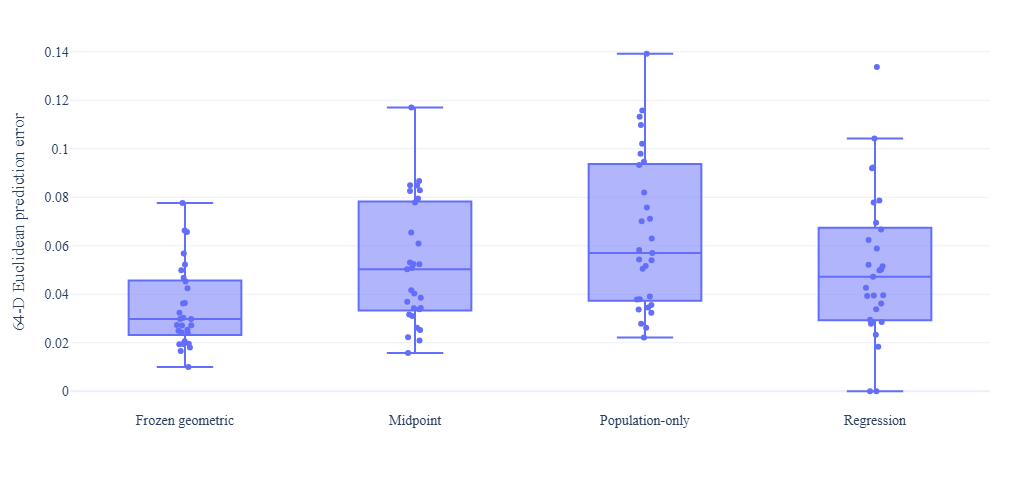

In [53]:
# ============================================================
# 16. STAGE 2 — FOUR-METHOD ERROR FIGURE
# ============================================================

plot_df = calibration_df.copy()

plot_df["Method"] = (
    plot_df["method"]
    .map(method_labels)
)

plot_df["Method"] = pd.Categorical(
    plot_df["Method"],
    categories=[
        method_labels[m]
        for m in METHOD_ORDER
    ],
    ordered=True,
)

fig = px.box(
    plot_df,
    x="Method",
    y="error_64D",
    points="all",
)

fig.update_traces(
    jitter=0.18,
    pointpos=0,
    marker=dict(size=6),
)

fig.update_layout(
    template="plotly_white",
    width=850,
    height=500,
    margin=dict(
        l=70,
        r=30,
        t=35,
        b=90,
    ),
    font=dict(
        family="Times New Roman",
        size=14,
    ),
    title=None,
    xaxis_title=None,
    yaxis_title="64-D Euclidean prediction error",
)

fig.show()

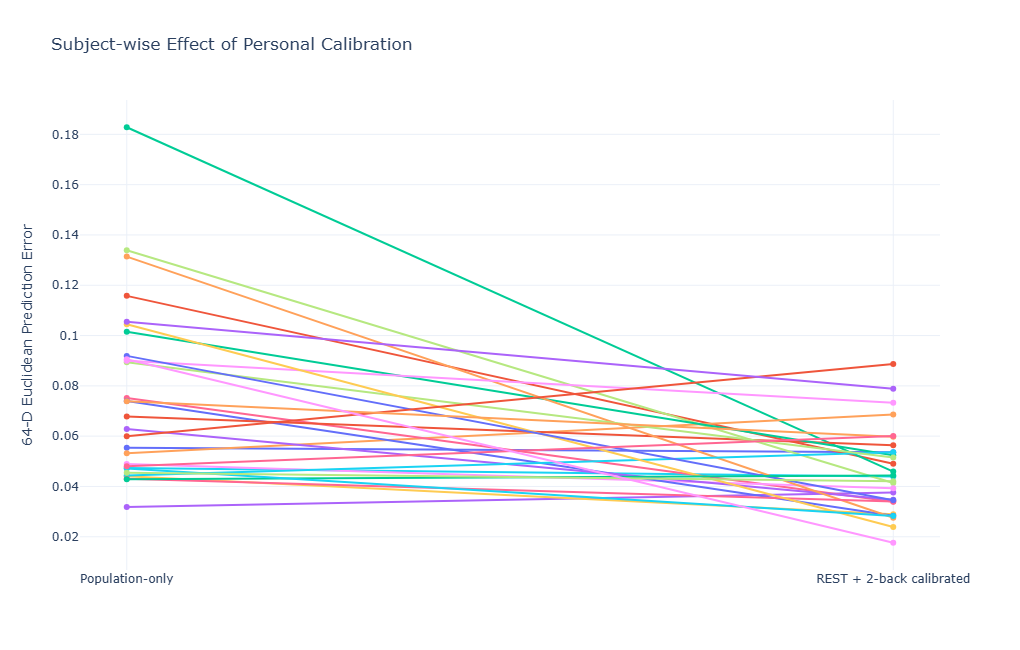

In [27]:
# ============================================================
# 17. SUBJECT-WISE CALIBRATION EFFECT
# ============================================================

fig = go.Figure()

for _, row in calibration_df.iterrows():

    fig.add_trace(
        go.Scatter(
            x=[
                "Population-only",
                "REST + 2-back calibrated"
            ],

            y=[
                row[baseline_col],
                row[calibrated_col]
            ],

            mode="lines+markers",

            showlegend=False,

            hovertemplate=(
                f"Subject {int(row['Subject'])}"
                "<br>%{x}"
                "<br>Error = %{y:.6f}"
                "<extra></extra>"
            )
        )
    )


fig.update_layout(
    title=(
        "Subject-wise Effect of Personal Calibration"
    ),

    yaxis_title=(
        "64-D Euclidean Prediction Error"
    ),

    template="plotly_white",

    height=650
)

fig.show()

# Final Demonstration Summary

## Stage 1

The demonstration uses a representative held-out subject from the
strict 29-fold LOSO evaluation.

The corresponding fold-specific best checkpoint and training-derived
normalization statistics are used to generate the unseen-subject
representation.

The notebook visualizes the subject's 64-D latent workload trajectory
and its relationship to the 28-subject population trajectory.

The all-subject quantitative evidence is loaded from the completed
29-fold LOSO evaluation artifacts. The primary trajectory criterion is
whether the 1-back centroid lies within the 0-back to 2-back segment;
distance ordering, path efficiency, perpendicular distance, Procrustes
similarity, and direction cosine provide supporting geometric evidence.

## Stage 2

Stage 2 keeps the fold-specific FIGNN encoder frozen and evaluates four
ways of estimating the held-out subject's 1-back latent centroid:

- population-only;
- midpoint;
- regression;
- frozen geometric calibration.

The true held-out 1-back centroid is used only as the evaluation target,
and methods are compared using 64-D Euclidean prediction error.

No encoder retraining or fine-tuning is performed during Stage 2.